In [1]:
# %pip install kagglehub
# %pip install plotly_express

# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

# print("Path to dataset files:", path)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import missingno as msno

from sklearn.model_selection import train_test_split #separação em treino e teste
from sklearn.neighbors import KNeighborsClassifier   #knn
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler, MinMaxScaler  

In [3]:
dados = pd.read_csv("data/data.csv", sep=",")

dados = dados.drop(
    columns=dados.filter(regex=r'(_worst|_se)$').columns
)

dados.head(1000)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,NaN


<Axes: >

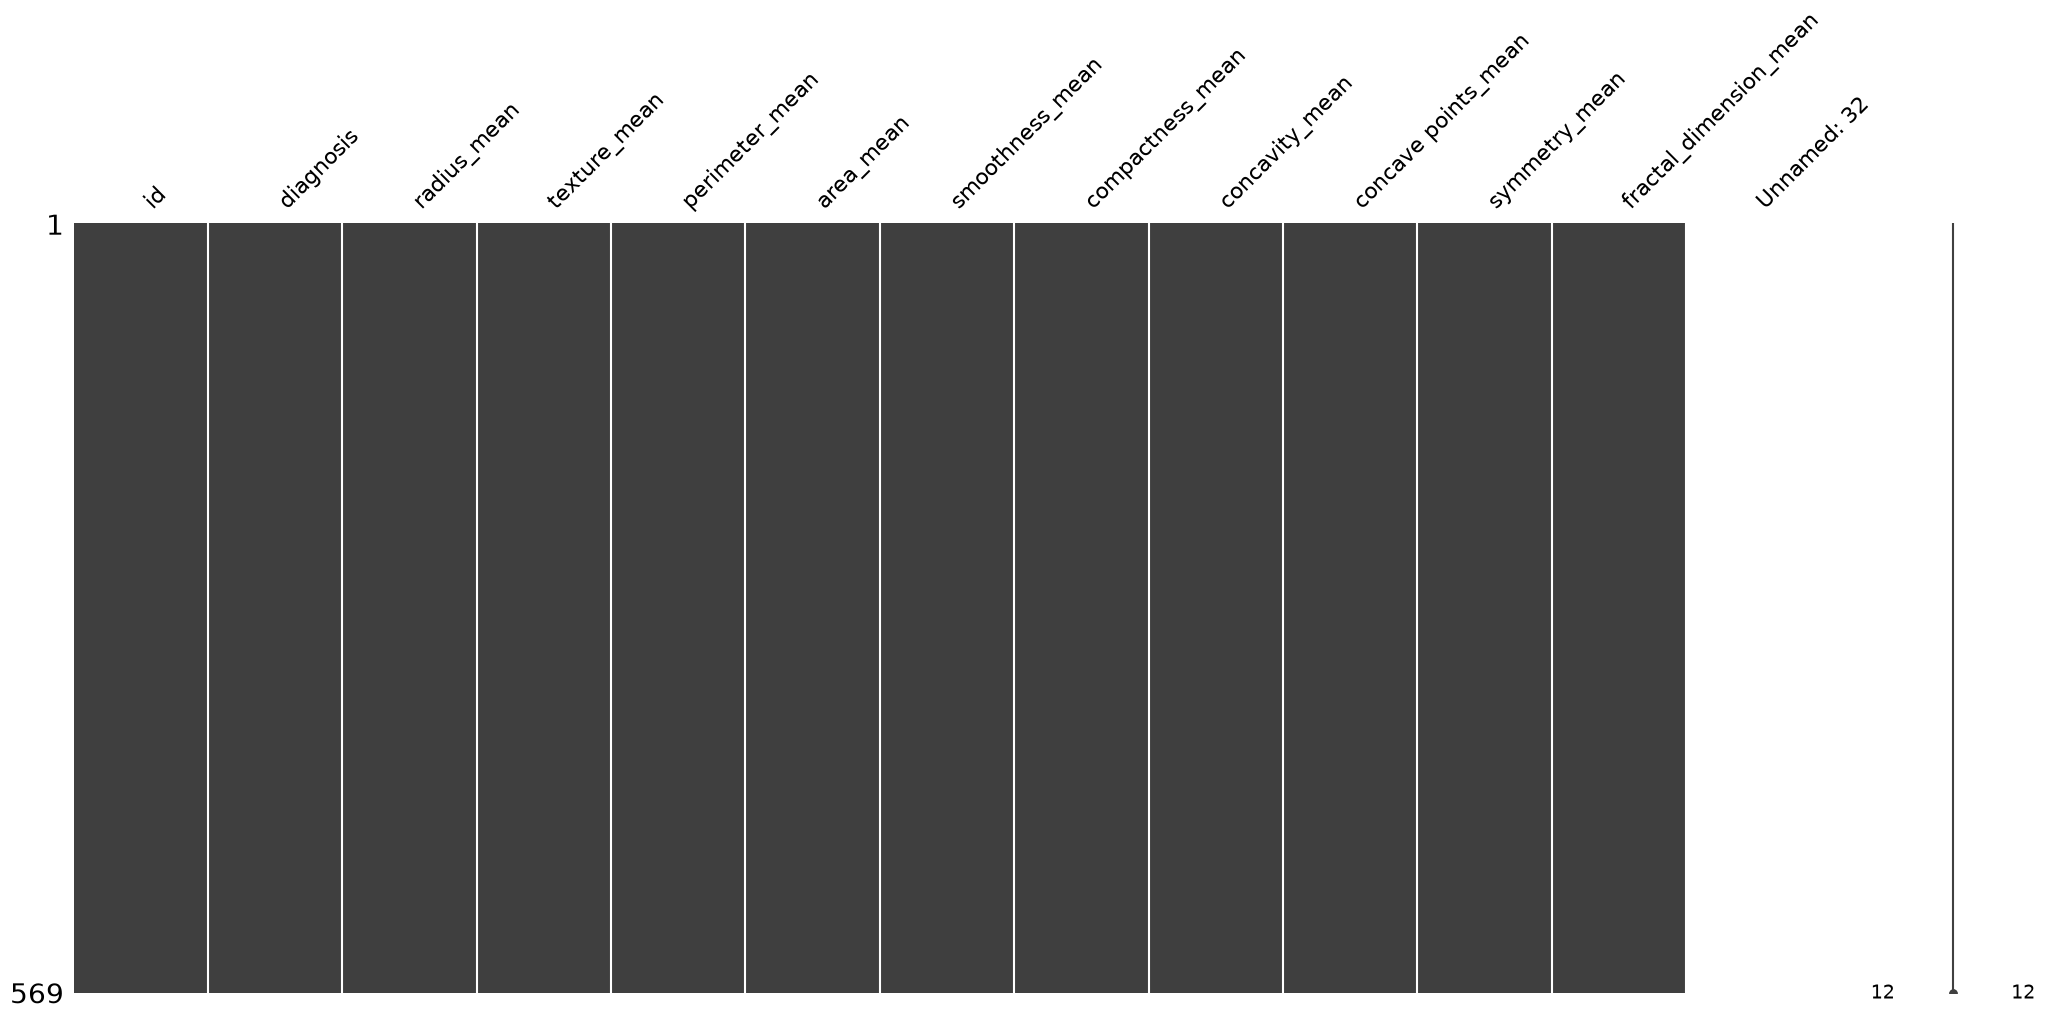

In [4]:
msno.matrix(dados)

In [5]:
dados.isnull().sum()

id                          0
diagnosis                   0
radius_mean                 0
texture_mean                0
perimeter_mean              0
area_mean                   0
smoothness_mean             0
compactness_mean            0
concavity_mean              0
concave points_mean         0
symmetry_mean               0
fractal_dimension_mean      0
Unnamed: 32               569
dtype: int64

<Axes: xlabel='diagnosis', ylabel='area_mean'>

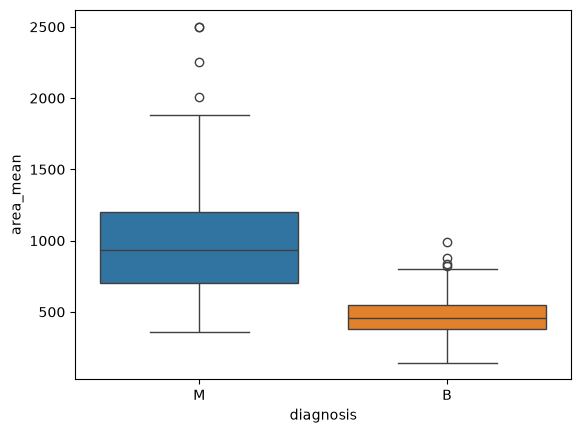

In [6]:
sns.boxplot(x=dados['diagnosis'], y=dados['area_mean'], hue=dados['diagnosis'])

<Axes: xlabel='diagnosis', ylabel='concavity_mean'>

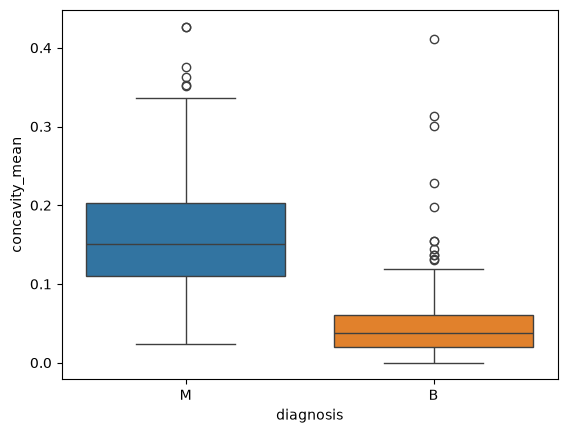

In [7]:
sns.boxplot(x=dados['diagnosis'], y=dados['concavity_mean'], hue=dados['diagnosis'])

<Axes: xlabel='diagnosis', ylabel='smoothness_mean'>

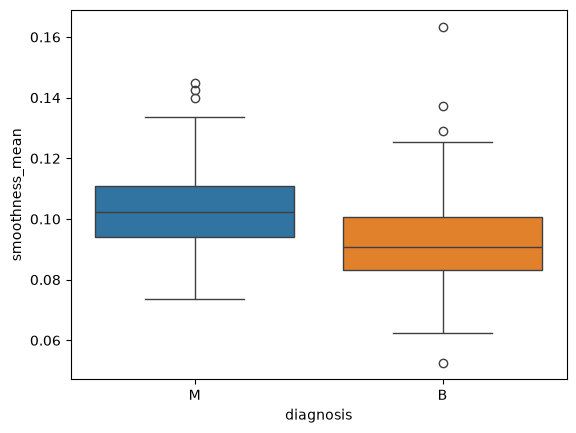

In [8]:
sns.boxplot(x=dados['diagnosis'], y=dados['smoothness_mean'], hue=dados['diagnosis'])

<Axes: xlabel='area_mean', ylabel='Count'>

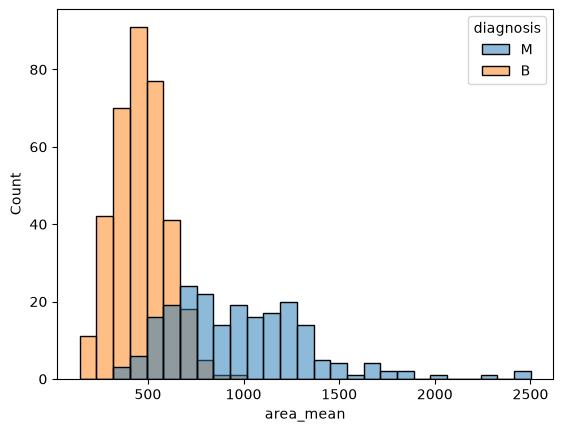

In [9]:
sns.histplot(data=dados, x="area_mean", hue="diagnosis")

C:\Users\hugo_\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 14.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


[Text(29.25, 0.5, 'Área média do tumor')]

C:\Users\hugo_\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 24.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


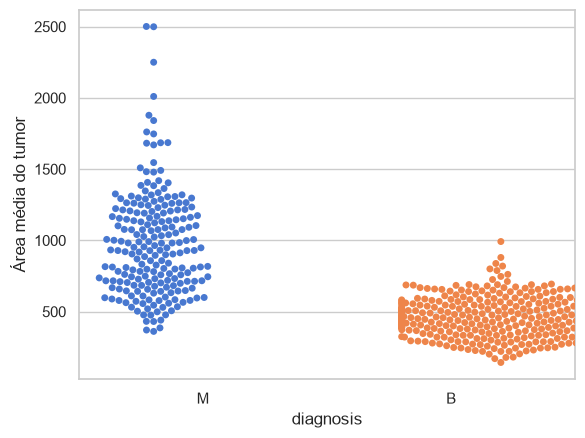

In [10]:
sns.set_theme(style="whitegrid", palette="muted")

ax = sns.swarmplot(data=dados, x="diagnosis", y="area_mean", hue="diagnosis", dodge=True, size=5)
ax.set(ylabel="Área média do tumor")

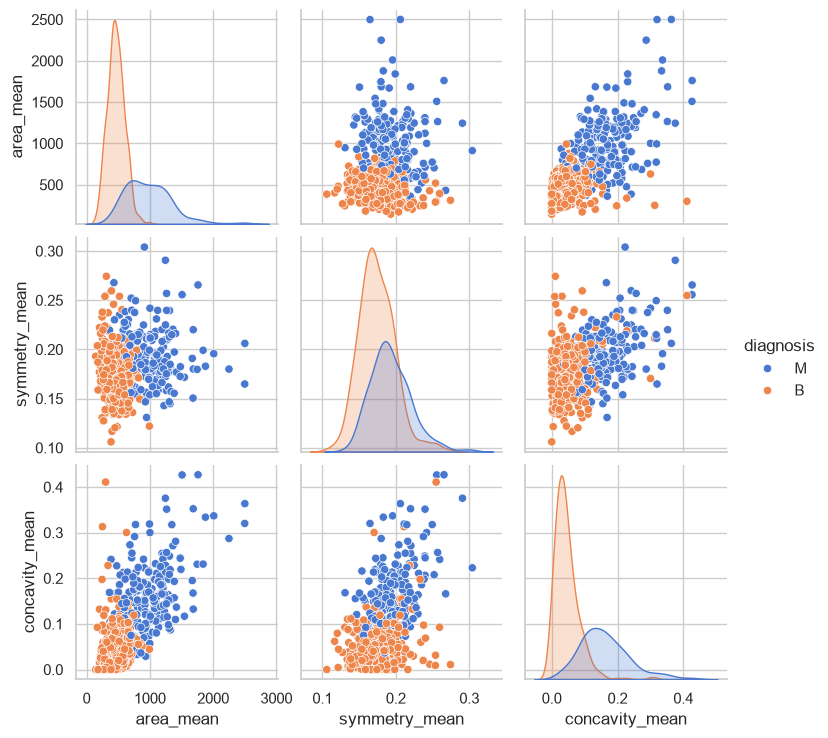

In [11]:
sns.pairplot(dados,vars=['area_mean','symmetry_mean', 'concavity_mean'],hue="diagnosis")

### area_mean × concavity_mean
Boa separação visual
Os tumores benignos estão mais concentrados no canto inferior esquerdo. Os malignos se espalham por regiões de área e concavidade maiores.

Isso sugere que combinar essas duas variáveis pode ajudar um classificador a diferenciar os diagnósticos.

### area_mean × symmetry_mean
A área ajuda a distinguir os grupos, mas a simetria apresenta sobreposição considerável. Portanto, a separação visual parece depender mais da área do que da simetria.

### symmetry_mean × concavity_mean
A concavidade ajuda a separar as classes, enquanto a simetria apresenta valores semelhantes nos dois grupos. Novamente, a concavidade parece contribuir mais para a distinção.

In [12]:
# Tratando os dados
dados = dados.drop(columns=['Unnamed: 32', 'id'], errors='ignore')
dados['diagnosis'] = dados['diagnosis'].map({
    'M': 1,
    'B': 0
})

In [13]:
dados.isnull().sum()

diagnosis                 0
radius_mean               0
texture_mean              0
perimeter_mean            0
area_mean                 0
smoothness_mean           0
compactness_mean          0
concavity_mean            0
concave points_mean       0
symmetry_mean             0
fractal_dimension_mean    0
dtype: int64

<Axes: >

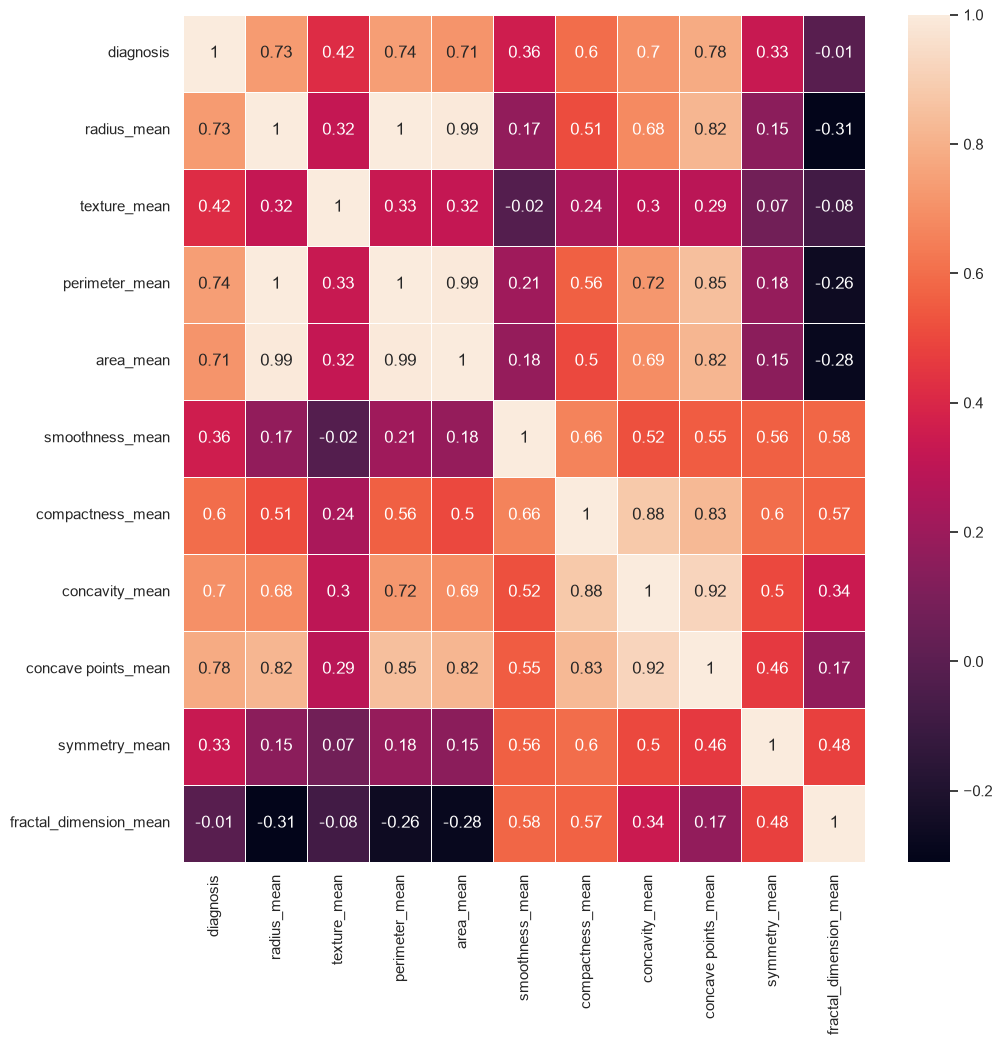

In [14]:
# Analisando correlações

correlation_matrix = dados.corr().round(2)
figsize = dados.shape[1]
fig, ax = plt.subplots(figsize=(figsize, figsize))
sns.heatmap(data=correlation_matrix, annot=True, linewidths=.5, ax=ax)

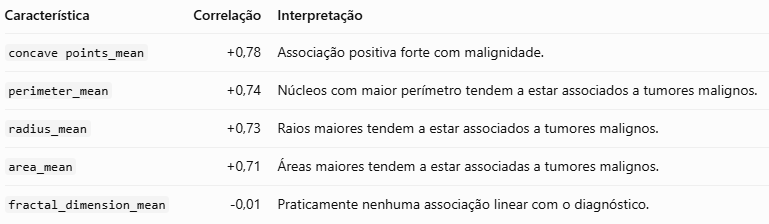

In [15]:
#Separando os dados
x = dados.drop(columns=['diagnosis'])
y = dados['diagnosis'] #O que eu quero prever. (Target)

In [16]:
#Separando em bases de treino e teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=7)

In [17]:
print("X treino:", x_train.shape)
print("X teste:", x_test.shape)

print("\nDistribuição do diagnóstico na base completa:")
print(y.value_counts())

print("\nDistribuição do diagnóstico no treino:")
print(y_train.value_counts())

print("\nDistribuição do diagnóstico no teste:")
print(y_test.value_counts())

X treino: (455, 10)
X teste: (114, 10)

Distribuição do diagnóstico na base completa:
diagnosis
0    357
1    212
Name: count, dtype: int64

Distribuição do diagnóstico no treino:
diagnosis
0    285
1    170
Name: count, dtype: int64

Distribuição do diagnóstico no teste:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [18]:
scaler = StandardScaler() 

scaler.fit(x_train)

x_train_escalonado = scaler.transform(x_train)
x_test_escalonado = scaler.transform(x_test) 

In [19]:

error = []

# Calculating error for K values between 1 and 10
for i in range(1, 10): #range de tentativas para k
    knn = KNeighborsClassifier(n_neighbors=i)# aqui definimos  o k
    knn.fit(x_train_escalonado, y_train) #treinando o algoritmo para encontrar o erro
    pred_i = knn.predict(x_test_escalonado) #armazenando as previsões
    error.append(np.mean(pred_i != y_test)) #armazenando o valor do erro médio na lista de erros

Text(0, 0.5, 'Mean Error')

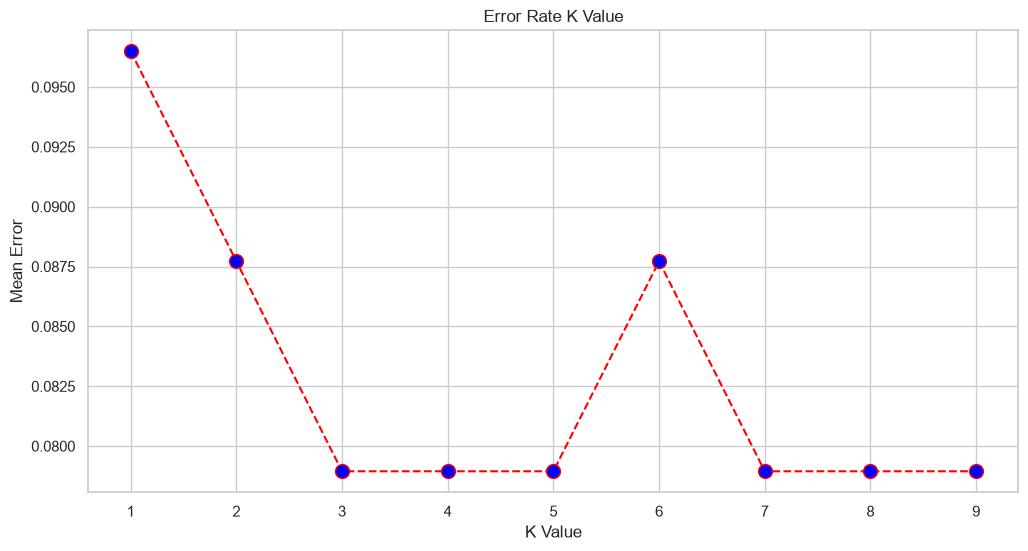

In [20]:

plt.figure(figsize=(12, 6))
plt.plot(range(1, 10), error, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Error Rate K Value')
plt.xlabel('K Value')
plt.ylabel('Mean Error')

In [21]:
modelo_classificador = KNeighborsClassifier(n_neighbors=5)
modelo_classificador.fit(x_train_escalonado, y_train)
y_predito = modelo_classificador.predict(x_test_escalonado) 

In [22]:
# Metricas de precisão, revocação, f1-score e acurácia.
print(accuracy_score(y_test, y_predito)) #relatório de validação das métrica de desempenho.

0.9210526315789473


In [23]:
# Testando o modelo SVM
svm = Pipeline([
    ("linear_svc", LinearSVC(C=1))
])

svm.fit(x_train_escalonado, y_train) 
y_predito_svm = svm.predict(x_test_escalonado) 
print(accuracy_score(y_test, y_predito_svm)) 

0.9210526315789473


In [24]:
# Testando o modelo Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Árvores não dependem da escala, então usamos os dados sem padronização
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest.fit(x_train, y_train)
y_predito_rf = random_forest.predict(x_test)
print(accuracy_score(y_test, y_predito_rf))

0.8859649122807017


In [25]:
# Comparando recall, precisão e matriz de confusão dos três modelos
for nome, predito in [('KNN', y_predito), ('SVM', y_predito_svm), ('Random Forest', y_predito_rf)]:
    print(nome)
    print(confusion_matrix(y_test, predito))
    print(classification_report(y_test, predito, digits=3))

KNN
[[69  3]
 [ 6 36]]
              precision    recall  f1-score   support

           0      0.920     0.958     0.939        72
           1      0.923     0.857     0.889        42

    accuracy                          0.921       114
   macro avg      0.922     0.908     0.914       114
weighted avg      0.921     0.921     0.920       114

SVM
[[70  2]
 [ 7 35]]


              precision    recall  f1-score   support

           0      0.909     0.972     0.940        72
           1      0.946     0.833     0.886        42

    accuracy                          0.921       114
   macro avg      0.928     0.903     0.913       114
weighted avg      0.923     0.921     0.920       114

Random Forest
[[69  3]
 [10 32]]
              precision    recall  f1-score   support

           0      0.873     0.958     0.914        72
           1      0.914     0.762     0.831        42

    accuracy                          0.886       114
   macro avg      0.894     0.860     0.873       114
weighted avg      0.888     0.886     0.883       114



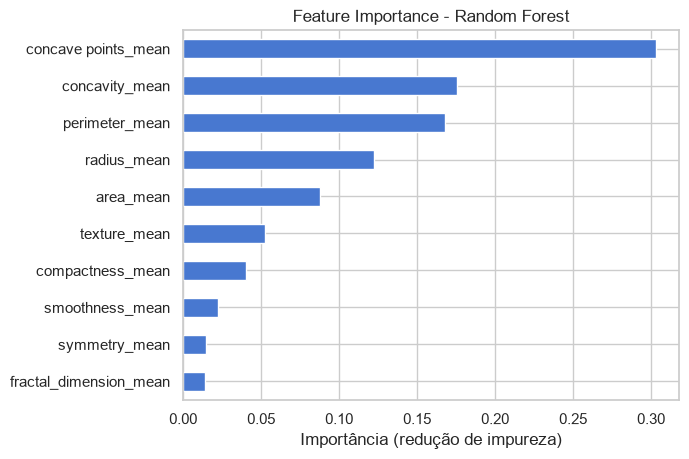

In [26]:
# Importância das variáveis segundo o Random Forest (redução de impureza)
importancias_rf = pd.Series(random_forest.feature_importances_, index=x_train.columns).sort_values()
importancias_rf.plot(kind='barh', legend=False)
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importância (redução de impureza)')
plt.show()

                  Feature  Importance       Std
4         smoothness_mean    0.078571  0.026190
1            texture_mean    0.069048  0.041853
8           symmetry_mean    0.054762  0.021429
6          concavity_mean    0.042857  0.034993
9  fractal_dimension_mean    0.030952  0.028272
7     concave points_mean    0.021429  0.034421
3               area_mean    0.016667  0.038465
0             radius_mean    0.009524  0.037192
2          perimeter_mean    0.009524  0.035635
5        compactness_mean    0.007143  0.021429


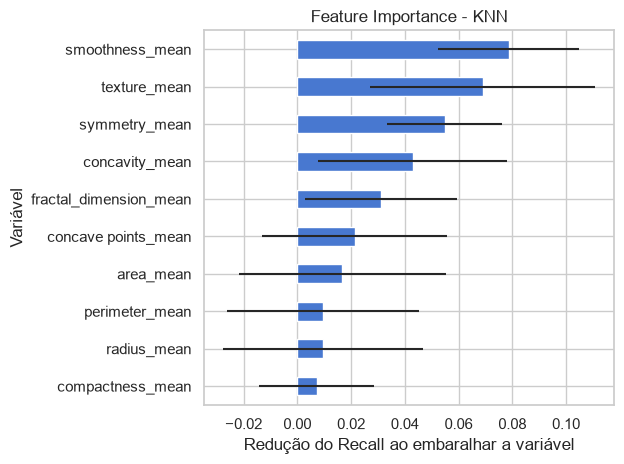

In [27]:
# Calcula a importância das variáveis
resultado = permutation_importance(
    modelo_classificador,
    x_test_escalonado,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='recall'
)

# Organiza os resultados
importancias = pd.DataFrame({
    'Feature': x_test.columns,
    'Importance': resultado.importances_mean,
    'Std': resultado.importances_std
})

# Ordena da maior para a menor importância
importancias = importancias.sort_values(
    by='Importance',
    ascending=False
)

# Exibe as 10 variáveis mais importantes
print(importancias.head(10))

# Gera o gráfico
importancias.head(10).sort_values('Importance').plot(
    x='Feature',
    y='Importance',
    kind='barh',
    legend=False,
    xerr='Std'
)

plt.title('Feature Importance - KNN')
plt.xlabel('Redução do Recall ao embaralhar a variável')
plt.ylabel('Variável')
plt.tight_layout()
plt.show()

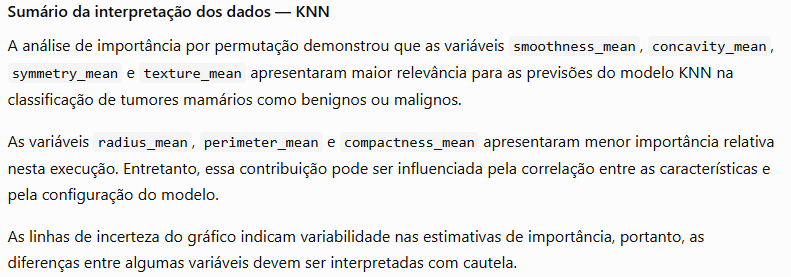